Linear Regression
MAE : 3013.1545694214365
RMSE : 5738.872473792815
R2 Score : 0.03958076121866849
Decision Tree
MAE : 3047.0285657160516
RMSE : 70953.84418375921
R2 Score : -145.81132645210138
Random Forest
MAE : 2487.876108271135
RMSE : 30401.37700759219
R2 Score : -25.95219951804942


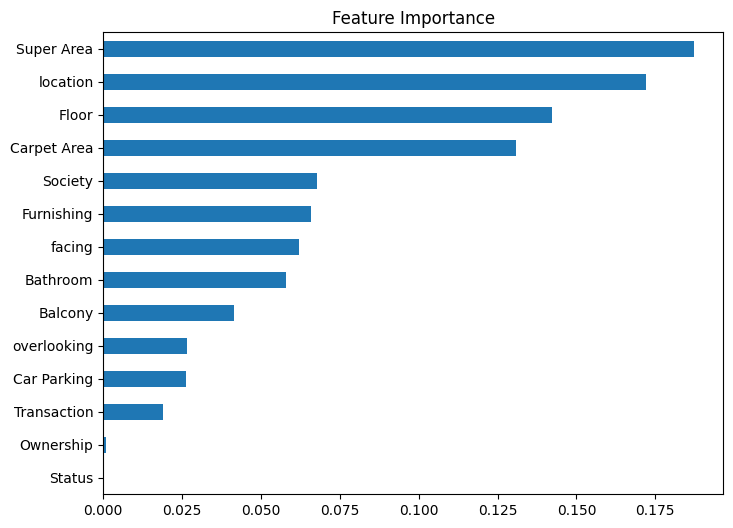


Predicted Price : 6388.6


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load Dataset
df = pd.read_csv("/content/house_prices.csv")

# Remove unwanted columns
drop_cols = [
    "Index",
    "Title",
    "Description",
    "Amount(in rupees)",
    "Plot Area",
    "Dimensions"
]

for col in drop_cols:
    if col in df.columns:
        df.drop(col, axis=1, inplace=True)

# Remove rows where target is missing
df.dropna(subset=["Price (in rupees)"], inplace=True)

# Fill Missing Values
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove Duplicates
df.drop_duplicates(inplace=True)

# Encode Categorical Columns
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Features and Target
X = df.drop("Price (in rupees)", axis=1)
y = df["Price (in rupees)"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# Evaluation
print("="*50)
print("Linear Regression")
print("MAE :", mean_absolute_error(y_test, lr_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score :", r2_score(y_test, lr_pred))

print("="*50)
print("Decision Tree")
print("MAE :", mean_absolute_error(y_test, dt_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, dt_pred)))
print("R2 Score :", r2_score(y_test, dt_pred))

print("="*50)
print("Random Forest")
print("MAE :", mean_absolute_error(y_test, rf_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score :", r2_score(y_test, rf_pred))

# Feature Importance
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values().plot(kind="barh", figsize=(8,6))
plt.title("Feature Importance")
plt.show()

# Save Model
joblib.dump(rf, "house_price_model.pkl")

# Predict First House
sample = X.iloc[[0]]
prediction = rf.predict(sample)
print("\nPredicted Price :", prediction[0])